# 06 · Final pipeline

Two parts, kept separate so that their effects can be told apart:

- **A. Data and inference strategies** with a *fixed* trained model: NMS threshold, test-time augmentation, sliced inference, ensembling (WBF).
- **B. Model / training-data changes** with a *fixed* inference setting: more training frames, full augmentation, longer training.

Finally the chosen configuration is retrained on **all** labelled clips and used for the test submission.

## 1. Setup

In [1]:
import os, sys, json, shutil, glob
from pathlib import Path

REPO = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path("..").resolve()
if Path("/kaggle").exists() and not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval ultralytics==8.3.*
sys.path.insert(0, str(REPO / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches, cv2
import vdet, parallel, ultra, infer
from vdet import CLASSES

vdet.seed_everything()
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle").exists() else REPO / "outputs"
RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
RESULT_DIRS = [RUNS, REPO / "results"]   # own runs + runs committed by the teammate
P = vdet.PROTOCOL

# restore finished runs from attached notebook outputs (02 Faster R-CNN, 04 YOLO, 06 Part B, 03, 05)
for cfg_file in glob.glob("/kaggle/input/**/runs/*/config.json", recursive=True):
    src = Path(cfg_file).parent
    if not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name); print("restored", src.name)


Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 153, done.
remote: Counting objects: 100% (153/153), done.
remote: Compressing objects: 100% (142/142), done.
remote: Total 153 (delta 47), reused 20 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (153/153), 16.10 MiB | 18.37 MiB/s, done.
Resolving deltas: 100% (47/47), done.
restored frcnn_e0_base
restored frcnn_e1_proposals
restored frcnn_e2_giou
restored frcnn_e3_roi_sampling
restored frcnn_e4_cosine
restored final_b1_step5
restored final_b2_fullaug
restored final_b3_24ep
restored yolo_y0_base
restored yolo_y1_p2
restored yolo_y2_imgsz1024
restored yolo_y2_imgsz1536
restored yolo_y3_tal13


In [2]:
imgs, anns = vdet.load_all(ROOT)
folds = pd.read_csv(OUT / "folds.csv") if (OUT / "folds.csv").exists() else vdet.make_folds(imgs, P["n_folds"])
folds.to_csv(OUT / "folds.csv", index=False)   # the parallel runner reads the split from this file
train_frames, val_frames = vdet.protocol_frames(imgs, folds, P)
train_gt = anns[anns.key.isin(train_frames.key) & (anns.iscrowd == 0)]
print(json.dumps(P))
print(f"train: {len(train_frames)} frames | val: {len(val_frames)} frames / {val_frames.clip_uid.nunique()} clips")

COLS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max", "ms_per_img", "epochs"]
def show(res, cols=COLS):
    cols = [c for c in cols if c in res]
    num = [c for c in cols if c not in ("ms_per_img", "epochs")]
    return res[cols].style.format("{:.4f}", subset=num).format("{:.1f}", subset=[c for c in ["ms_per_img"] if c in cols])

{"val_fold": 0, "n_folds": 5, "step": 10, "val_step": 10, "imgsz": 1280, "epochs": 12, "seed": 42}
train: 2189 frames | val: 545 frames / 12 clips


,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
frcnn_e1_proposals,0.2561,0.4795,0.2441,0.1094,0.2032,0.4448,0.3902,114.3,12
final_b2_fullaug,0.2366,0.4288,0.2264,0.1150,0.1773,0.3953,0.3514,17.5,12
yolo_y2_imgsz1536,0.2097,0.4052,0.1939,0.0926,0.1766,0.3248,0.3199,30.5,12


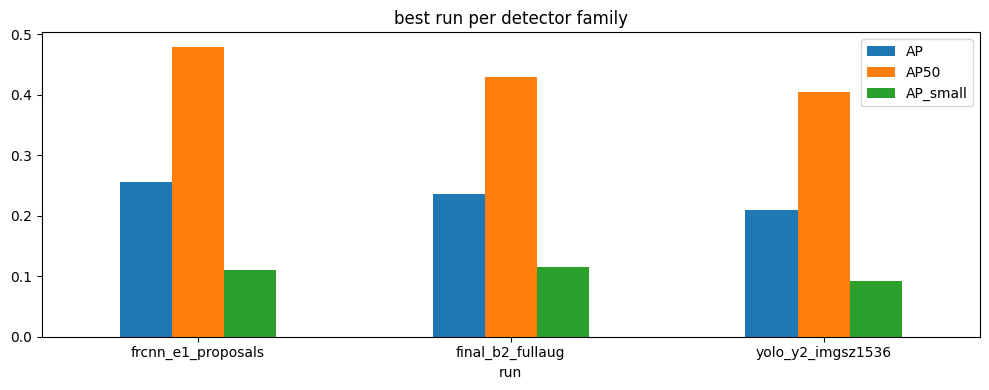

In [3]:
# All model results so far (own runs + teammate's committed results/)
allres = vdet.collect_results(RESULT_DIRS)
if len(allres):
    allres["family"] = allres.index.str.split("_").str[0]
    best = allres.loc[allres.groupby("family").AP.idxmax()].sort_values("AP", ascending=False)
    display(show(best))
    best[["AP", "AP50", "AP_small"]].plot.bar(figsize=(10, 4), rot=0, title="best run per detector family")
    plt.tight_layout(); plt.savefig(OUT / "summary_all_models.png", dpi=120); plt.show()

## 1b. Quick submissions: best single model and its ensemble with Faster R-CNN

Before the longer experiments, write two test submissions from models that are already trained: YOLOv8s with full augmentation (Part B, B2) and its WBF ensemble with Faster R-CNN E1. The holdout check below decides the ensemble weights.

In [4]:
# Holdout check on saved validation predictions (no GPU needed)
vb2 = pd.read_csv(RUNS / "final_b2_fullaug" / "val_preds.csv.gz")
vfr = pd.read_csv(RUNS / "frcnn_e1_proposals" / "val_preds.csv.gz")
Q = {"B2 alone": vb2, "Faster R-CNN E1 alone": vfr,
     "WBF B2+FRCNN 1:1": infer.wbf([vb2, vfr], weights=[1, 1], iou_thr=0.55),
     "WBF B2+FRCNN 1:2": infer.wbf([vb2, vfr], weights=[1, 2], iou_thr=0.55)}
tabQ = pd.DataFrame({k: vdet.coco_evaluate(val_frames, anns, v, per_class=False) for k, v in Q.items()}).T
display(tabQ[["AP", "AP50", "AP_small", "AP_medium"]].style.format("{:.4f}").highlight_max(color="#cde"))

,AP,AP50,AP_small,AP_medium
B2 alone,0.2366,0.4288,0.1150,0.1773
Faster R-CNN E1 alone,0.2561,0.4795,0.1094,0.2032
WBF B2+FRCNN 1:1,0.2820,0.5139,0.1282,0.2241
WBF B2+FRCNN 1:2,0.2749,0.5025,0.1211,0.2179


In [5]:
# Test submissions: B2 alone and both WBF weightings
tb2 = ultra.predict_test(ultra.load(RUNS / "final_b2_fullaug"), ROOT, 1280)
tb2.to_csv(OUT / "test_preds_final_b2_fullaug.csv.gz", index=False)
vdet.write_submission(tb2, ROOT / "test_images.csv", OUT / "submission_b2.csv")
tfr = pd.read_csv(glob.glob("/kaggle/input/**/test_preds_frcnn_e1_proposals.csv.gz", recursive=True)[0])
for w in ([1, 1], [1, 2]):
    fused = infer.wbf([tb2.rename(columns={"image_id": "key"}), tfr.rename(columns={"image_id": "key"})],
                      weights=w, iou_thr=0.55).rename(columns={"key": "image_id"})
    vdet.write_submission(fused, ROOT / "test_images.csv", OUT / f"submission_wbf_b2_frcnn_{w[0]}{w[1]}.csv")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
submission OK: 3811 rows, 3811 non-empty
submission OK: 3811 rows, 3811 non-empty
submission OK: 3811 rows, 3811 non-empty


## 2. Part A — inference strategies on a fixed model

In [6]:
# The best single model. Its run folder must be available: own RUNS, or attach the teammate's
# Kaggle notebook output as input (the setup cell copies */runs/* automatically).
BASE_RUN = "final_b2_fullaug"   # best YOLO (Part B, full augmentation)
cfg = json.loads((RUNS / BASE_RUN / "config.json").read_text()); IMGSZ = cfg["imgsz"]
model = ultra.load(RUNS / BASE_RUN)
A = {}
def evalA(name, preds):
    A[name] = vdet.coco_evaluate(val_frames, anns, preds, per_class=False); print(name, {k: round(v, 4) for k, v in A[name].items()})
    return preds

In [7]:
# A1: NMS IoU threshold -- dense scenes have true neighbours that overlap
for iou in [0.5, 0.6, 0.7]:
    evalA(f"A1 nms_iou={iou}", ultra.predict_frames(model, val_frames, IMGSZ, iou=iou))

A1 nms_iou=0.5 {'AP': 0.2348, 'AP50': 0.427, 'AP75': 0.2244, 'AP_small': 0.1147, 'AP_medium': 0.1758, 'AP_large': 0.3939, 'AR_max': 0.3446}
A1 nms_iou=0.6 {'AP': 0.2366, 'AP50': 0.4288, 'AP75': 0.2264, 'AP_small': 0.115, 'AP_medium': 0.1773, 'AP_large': 0.3953, 'AR_max': 0.3514}
A1 nms_iou=0.7 {'AP': 0.2375, 'AP50': 0.428, 'AP75': 0.228, 'AP_small': 0.1154, 'AP_medium': 0.1783, 'AP_large': 0.3964, 'AR_max': 0.3591}


In [8]:
NMS_IOU = 0.6   # set from A1
# A2: test-time augmentation (Ultralytics: flips + 2 extra scales, merged before NMS)
evalA("A2 TTA", ultra.predict_frames(model, val_frames, IMGSZ, iou=NMS_IOU, augment=True))

A2 TTA {'AP': 0.2514, 'AP50': 0.4541, 'AP75': 0.2385, 'AP_small': 0.1151, 'AP_medium': 0.1877, 'AP_large': 0.4222, 'AR_max': 0.3882}


,key,cls,score,x,y,w,h
0,train/uav0000020_00406_v/0000001,0,0.814453,974.924927,506.099976,44.100037,108.150024
1,train/uav0000020_00406_v/0000001,0,0.782715,952.874939,492.449982,37.799988,98.699982
2,train/uav0000020_00406_v/0000001,0,0.710449,809.549988,400.574982,23.099976,75.600006
3,train/uav0000020_00406_v/0000001,0,0.706543,919.799988,510.824982,29.399963,69.300018
4,train/uav0000020_00406_v/0000001,0,0.687500,639.449951,387.449982,29.400024,71.399994
...,...,...,...,...,...,...,...
133821,val/uav0000117_02622_v/0000341,0,0.012337,2422.500000,898.343750,42.500000,76.500000
133822,val/uav0000117_02622_v/0000341,0,0.012009,429.781250,634.843750,40.375000,92.437500
133823,val/uav0000117_02622_v/0000341,0,0.011963,1753.125000,430.843750,68.000000,56.312500
133824,val/uav0000117_02622_v/0000341,0,0.011963,2034.687500,555.156250,34.000000,62.687500


In [9]:
# A3: sliced inference -- crops are upscaled to IMGSZ by the model, i.e. a zoom-in on tiny objects
fn = lambda ims: ultra.predict_images(model, ims, IMGSZ, iou=NMS_IOU)
for tile in [640, 960]:
    evalA(f"A3 sliced tile={tile}", infer.sliced_predict(fn, val_frames, tile=tile, overlap=0.2, full=True, merge_iou=NMS_IOU))

A3 sliced tile=640 {'AP': 0.2355, 'AP50': 0.4339, 'AP75': 0.2169, 'AP_small': 0.1187, 'AP_medium': 0.1865, 'AP_large': 0.3668, 'AR_max': 0.4047}
A3 sliced tile=960 {'AP': 0.2461, 'AP50': 0.4539, 'AP75': 0.2308, 'AP_small': 0.1423, 'AP_medium': 0.2072, 'AP_large': 0.3745, 'AR_max': 0.4074}


In [10]:
# A4: WBF ensemble of the best run of each family (saved val predictions -> no GPU needed)
pred_files = {}
for run in (best.index if len(allres) else []):
    f = next((Path(d) / run / "val_preds.csv.gz" for d in RESULT_DIRS if (Path(d) / run / "val_preds.csv.gz").exists()), None)
    if f is not None: pred_files[run] = f
print("models available for the ensemble:", list(pred_files))
val_preds = {r: pd.read_csv(f) for r, f in pred_files.items()}
order = sorted(val_preds, key=lambda r: -best.loc[r, "AP"])
for k in range(2, len(order) + 1):
    runs = order[:k]
    evalA(f"A4 WBF {'+'.join(runs)}", infer.wbf([val_preds[r] for r in runs], weights=[best.loc[r, "AP"] for r in runs], iou_thr=0.55))

models available for the ensemble: ['frcnn_e1_proposals', 'final_b2_fullaug', 'yolo_y2_imgsz1536']
A4 WBF frcnn_e1_proposals+final_b2_fullaug {'AP': 0.2819, 'AP50': 0.5143, 'AP75': 0.2691, 'AP_small': 0.1276, 'AP_medium': 0.2241, 'AP_large': 0.4627, 'AR_max': 0.4288}
A4 WBF frcnn_e1_proposals+final_b2_fullaug+yolo_y2_imgsz1536 {'AP': 0.2837, 'AP50': 0.52, 'AP75': 0.2708, 'AP_small': 0.1307, 'AP_medium': 0.2356, 'AP_large': 0.4564, 'AR_max': 0.4383}


In [11]:
tabA = pd.DataFrame(A).T[["AP", "AP50", "AP_small", "AP_medium"]]
display(tabA.style.format("{:.4f}").highlight_max(color="#cde"))

,AP,AP50,AP_small,AP_medium
A1 nms_iou=0.5,0.2348,0.4270,0.1147,0.1758
A1 nms_iou=0.6,0.2366,0.4288,0.1150,0.1773
A1 nms_iou=0.7,0.2375,0.4280,0.1154,0.1783
A2 TTA,0.2514,0.4541,0.1151,0.1877
A3 sliced tile=640,0.2355,0.4339,0.1187,0.1865
A3 sliced tile=960,0.2461,0.4539,0.1423,0.2072
A4 WBF frcnn_e1_proposals+final_b2_fullaug,0.2819,0.5143,0.1276,0.2241
A4 WBF frcnn_e1_proposals+final_b2_fullaug+yolo_y2_imgsz1536,0.2837,0.5200,0.1307,0.2356


## 3. Part B — training data / model changes with fixed inference

In [12]:
# B1: denser frame sampling (step 5 instead of 10); B2: full Ultralytics augmentation (mosaic, scale, HSV);
# B3: longer training. All on the BASE_RUN architecture, evaluated with plain inference.
data5 = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0_step5",
                                step=5, val_step=P["val_step"])
data10 = OUT / "yolo_fold0" / "data.yaml"
if not data10.exists():
    data10 = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0",
                                     step=P["step"], val_step=P["val_step"])
FULL_AUG = dict(mosaic=1.0, scale=0.5, translate=0.1, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, close_mosaic=3)
# Part B was run on top of yolo_y0_base (notebook "06 Part B"); its finished runs are restored from the
# attached output and skipped here, so this cell only reprints the comparison.
cfg0 = json.loads((RUNS / "yolo_y0_base" / "config.json").read_text())
B = {"final_b1_step5": (data5, {**cfg0}),
     "final_b2_fullaug": (data10, {**cfg0, "aug": FULL_AUG}),
     "final_b3_24ep": (data10, {**cfg0, "epochs": 2 * cfg0["epochs"]})}
RUN_B = ["final_b1_step5", "final_b2_fullaug", "final_b3_24ep"]
# each job carries its own dataset; with 2 GPUs b1 + b2 run together, then b3
parallel.run_parallel([(n, B[n][1], B[n][0]) for n in RUN_B], RUNS, folds_csv=OUT / "folds.csv")
display(show(pd.concat([vdet.collect_results(RESULT_DIRS, "yolo_y0_base"), vdet.collect_results(RESULT_DIRS, "final_b")])))

train:   4353 frames,  3119 masked copies
val  :    545 frames,   409 masked copies
train:   2189 frames,  1570 masked copies
val  :    545 frames,   409 masked copies
final_b1_step5: already finished, skipped
final_b2_fullaug: already finished, skipped
final_b3_24ep: already finished, skipped
0 jobs on GPUs [0, 1]


,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
yolo_y0_base,0.2028,0.3653,0.1958,0.0959,0.1533,0.3495,0.3058,23.3,12
final_b1_step5,0.1925,0.3464,0.1867,0.0715,0.1518,0.3196,0.2765,24.2,12
final_b2_fullaug,0.2366,0.4288,0.2264,0.1150,0.1773,0.3953,0.3514,17.5,12
final_b3_24ep,0.1921,0.3480,0.1844,0.0925,0.1413,0.3325,0.2783,19.1,24


## 4. Final model: chosen settings, trained on all labelled clips

In [13]:
FINAL_CFG = {**cfg}            # cfg of final_b2_fullaug: yolov8s, 1280, full augmentation
FINAL_STEP = 10                # step 5 did not help (B1)
data_all = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_all",
                                   step=FINAL_STEP, val_step=P["val_step"], train_all=True)
# val metrics of this run are optimistic (holdout is in training); they are only a sanity check
parallel.run_parallel([("final_all_clips", FINAL_CFG)], RUNS, folds_csv=OUT / "folds.csv", data_yaml=data_all)

train:   2734 frames,  1979 masked copies
val  :    545 frames,   409 masked copies
1 jobs on GPUs [0, 1]
[   0.0 min] started final_all_clips on GPU 0
[   0.5 min] final_all_clips (GPU 0): train: Scanning /kaggle/working/yolo_all/labels/train/train__uav0000013_00000_v... 852 images, 0 backgrounds, 0 corrupt: 31% ━━━╸──────── 852/2734 656.7it/s 1.7s<2.9s
[  10.5 min] final_all_clips (GPU 0):        3/12      11.2G      1.529     0.9745      1.093        663       1280: 96% ━━━━━━━━━━━─ 327/342 1.7it/s 3:05<8.6s
[  20.5 min] final_all_clips (GPU 0):        6/12      11.6G      1.453     0.8449       1.06        930       1280: 89% ━━━━━━━━━━╸─ 304/342 1.8it/s 2:53<21.6s
[  30.5 min] final_all_clips (GPU 0):        9/12      10.9G      1.369     0.7471      1.029        641       1280: 82% ━━━━━━━━━╸── 282/342 1.8it/s 2:40<33.9s
[  40.5 min] final_all_clips (GPU 0):       12/12      9.03G      1.317     0.6835      1.028        372       1280: 96% ━━━━━━━━━━━─ 327/342 1.9it/s 2:53<8.0s
[

{'final_all_clips': 0}

In [14]:
# Test predictions with the inference strategy chosen in Part A
final = ultra.load(RUNS / "final_all_clips")
test = pd.read_csv(ROOT / "test_images.csv")
test_frames = test.assign(key=test.image_id, img_path=[str(ROOT / f) for f in test.file_name])
STRATEGY = "plain"   # "plain", "tta" or "sliced", from Part A
if STRATEGY == "sliced":
    fn = lambda ims: ultra.predict_images(final, ims, FINAL_CFG["imgsz"], iou=NMS_IOU)
    tp = infer.sliced_predict(fn, test_frames, tile=640, overlap=0.2, merge_iou=NMS_IOU)
else:
    tp = ultra.predict_frames(final, test_frames, FINAL_CFG["imgsz"], iou=NMS_IOU, augment=STRATEGY == "tta")
tp = tp.rename(columns={"key": "image_id"})
tp.to_csv(OUT / "test_preds_final.csv.gz", index=False)
vdet.write_submission(tp, ROOT / "test_images.csv", OUT / "submission_final.csv")

submission OK: 3811 rows, 3811 non-empty


,image_id,PredictionString
0,clip_001_0000001,0 0.7725 774.0 887.2 69.0 165.0 0 0.7319 1653....
1,clip_001_0000002,0 0.7847 774.0 893.2 69.0 169.5 0 0.7241 624.4...
2,clip_001_0000003,0 0.7710 1665.0 796.5 66.0 153.0 0 0.7500 1725...
3,clip_001_0000004,0 0.7793 756.0 903.0 72.0 168.0 0 0.7407 1666....
4,clip_001_0000005,0 0.7710 722.2 916.5 75.0 157.5 0 0.7271 1662....
...,...,...
3806,clip_048_0000041,2 0.8374 771.4 360.2 59.5 62.2 2 0.8091 982.8 ...
3807,clip_048_0000042,2 0.8408 772.4 350.1 59.5 61.6 2 0.8115 795.8 ...
3808,clip_048_0000043,2 0.8550 65.6 234.8 77.9 61.1 2 0.8301 772.4 3...
3809,clip_048_0000044,2 0.8345 772.4 337.6 57.4 60.0 2 0.8130 59.8 2...


In [15]:
# WBF of the final model with Faster R-CNN E1 test predictions (02 Faster R-CNN output attached).
# Add other runs to FUSE only if they improved the ensemble on the holdout (Part A4 / Section 1b).
FUSE = ["frcnn_e1_proposals"]
others = [f for r in FUSE for f in glob.glob(f"/kaggle/input/**/test_preds_{r}.csv.gz", recursive=True)[:1]]
print([Path(o).name for o in others])
if others:
    parts = [tp] + [pd.read_csv(o) for o in others]
    fused = infer.wbf([p.rename(columns={"image_id": "key"}) for p in parts], iou_thr=0.55).rename(columns={"key": "image_id"})
    vdet.write_submission(fused, ROOT / "test_images.csv", OUT / "submission_final_wbf.csv")

['test_preds_frcnn_e1_proposals.csv.gz']
submission OK: 3811 rows, 3811 non-empty


In [16]:
# Results for the repo: unzip results.zip from the notebook Output into <repo>/results/ and commit.
vdet.export_results(RUNS, OUT / "results", preds_for=("final_all_clips",))

results archive: /kaggle/working/results.zip


PosixPath('/kaggle/working/results.zip')